In [ ]:
import os
import matplotlib.pyplot as plt
import cv2
from deepface import DeepFace
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

c:\Users\abdel\Downloads\plk1\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


This is for evaluating the DeepFace ArcFace model, we chose this model for it's light weight even though it took 240min to evaluate all the images in the "./img/data/test" directory to get a good evaluation to the model

In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from tqdm import tqdm

db_path = "./img/data/test"
model_name = "VGG-Face"
backend = "retinaface"
metric = "cosine"

y_true = []
y_pred = []

all_images = []
for person_name in os.listdir(db_path):
    person_folder = os.path.join(db_path, person_name)
    if os.path.isdir(person_folder):
        for img_file in os.listdir(person_folder):
            if img_file.lower().endswith(('.png', '.jpg', '.jpeg')):
                full_path = os.path.join(person_folder, img_file)
                # Store (Actual Name, Image Path)
                all_images.append((person_name, full_path))

print(f"Running identification on {len(all_images)} images...")

# eval loop
for true_name, img_path in tqdm(all_images):

    # Ground Truth
    y_true.append(true_name)

    try:
        dfs = DeepFace.find(img_path=img_path,
                            db_path=db_path,
                            model_name=model_name,
                            detector_backend=backend,
                            distance_metric=metric,
                            enforce_detection=False)

        predicted_label = "Unidentified"

        if len(dfs) > 0 and not dfs[0].empty:
            df = dfs[0]
            df = df[df['identity'] != img_path]

            if not df.empty:
                # Get the top match (Rank-1)
                top_match_path = df.iloc[0]['identity']

                # Extract the folder name from the full path
                predicted_label = os.path.basename(os.path.dirname(top_match_path))

        y_pred.append(predicted_label)

    except Exception as e:
        print(f"Error on {img_path}: {e}")
        y_pred.append("Error")

print("\n--- Overall Metrics ---")
# accuracy_score
acc = accuracy_score(y_true, y_pred)
print(f"Global Accuracy: {acc:.2%}")

print("\n--- Detailed Report per Celebrity ---")
# Precision, Recall, F1-Score for EACH person
print(classification_report(y_true, y_pred, zero_division=0))

Running identification on 3555 images...


  0%|          | 0/3555 [00:00<?, ?it/s]

26-01-24 09:22:15 - Searching ./data/test\pins_Adriana Lima\Adriana Lima50_172.jpg in 3564 length datastore


  0%|          | 1/3555 [00:01<1:19:15,  1.34s/it]

26-01-24 09:22:16 - find function duration 1.320418119430542 seconds
26-01-24 09:22:16 - Searching ./data/test\pins_Adriana Lima\Adriana Lima51_173.jpg in 3564 length datastore


  0%|          | 2/3555 [00:02<1:16:39,  1.29s/it]

... (355 outputs left out)

  5%|▌         | 180/3555 [04:21<1:52:02,  1.99s/it]

26-01-24 09:26:36 - find function duration 1.8930599689483643 seconds
26-01-24 09:26:37 - Searching ./data/test\pins_alycia dabnem carey\alycia dabnem carey91_202.jpg in 3564 length datastore


  5%|▌         | 181/3555 [04:23<1:48:06,  1.92s/it]

26-01-24 09:26:38 - find function duration 1.7390568256378174 seconds
26-01-24 09:26:38 - Searching ./data/test\pins_alycia dabnem carey\alycia dabnem carey92_203.jpg in 3564 length datastore


In [ ]:
print("\n--- Overall Metrics ---")
# accuracy_score: Global percentage of correct identifications
acc = accuracy_score(y_true, y_pred)
print(f"Global Accuracy: {acc:.2%}")

print("\n--- Detailed Report per Celebrity ---")
# classification_report: Precision, Recall, F1-Score for EACH person
# zero_division=0 prevents warnings for "Unidentified" classes
print(classification_report(y_true, y_pred, zero_division=0))


--- Overall Metrics ---


NameError: name 'accuracy_score' is not defined

Saved parsed metrics to ./report_visuals\parsed_metrics_from_preds.csv


Saved parsed metrics to ./report_visuals\parsed_metrics_from_preds.csv


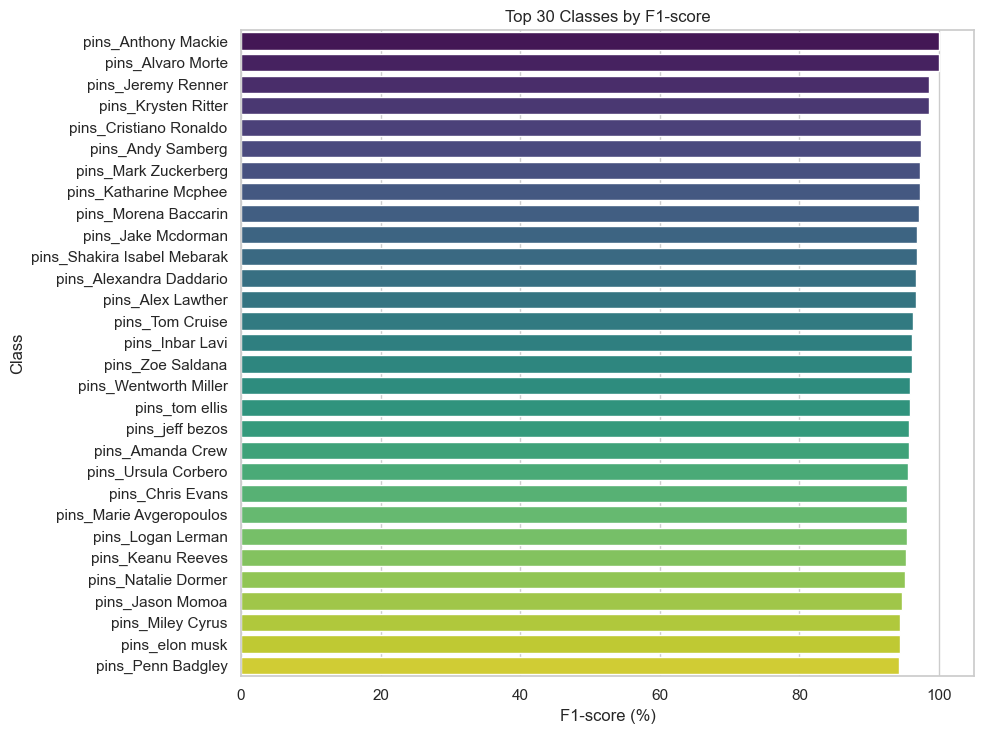

Saved parsed metrics to ./report_visuals\parsed_metrics_from_preds.csv


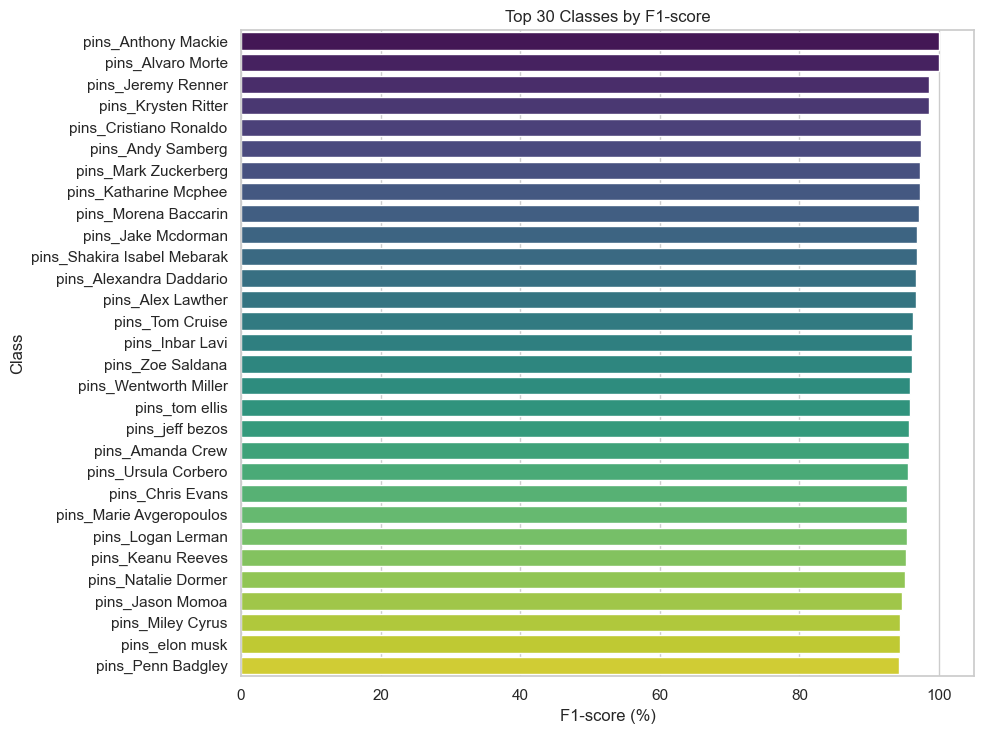

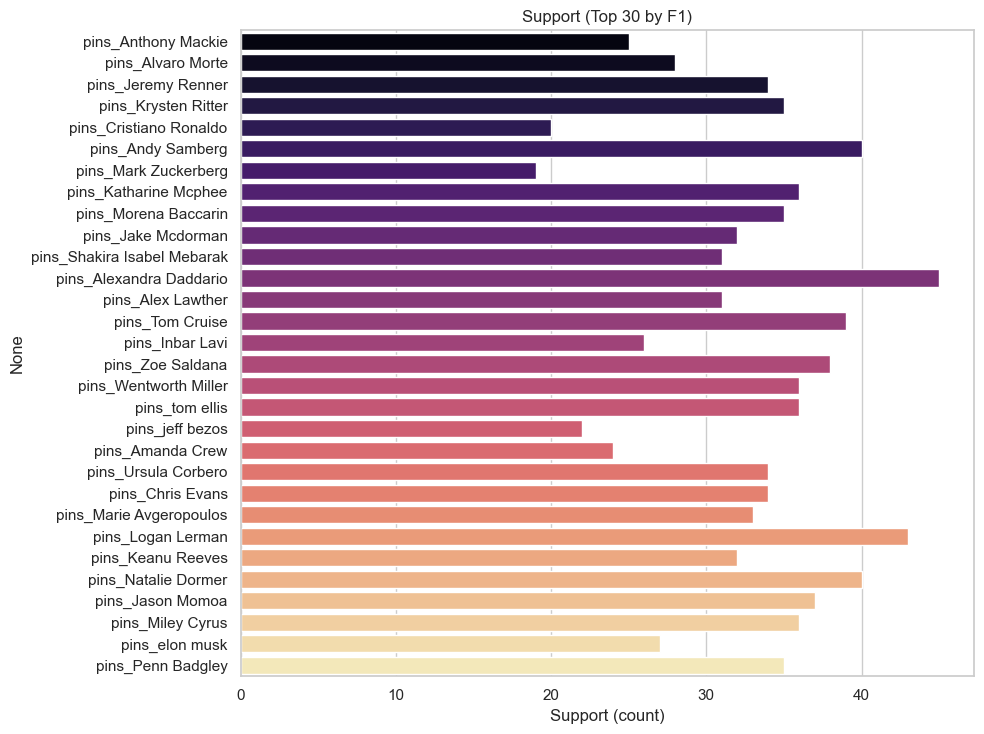

Saved parsed metrics to ./report_visuals\parsed_metrics_from_preds.csv


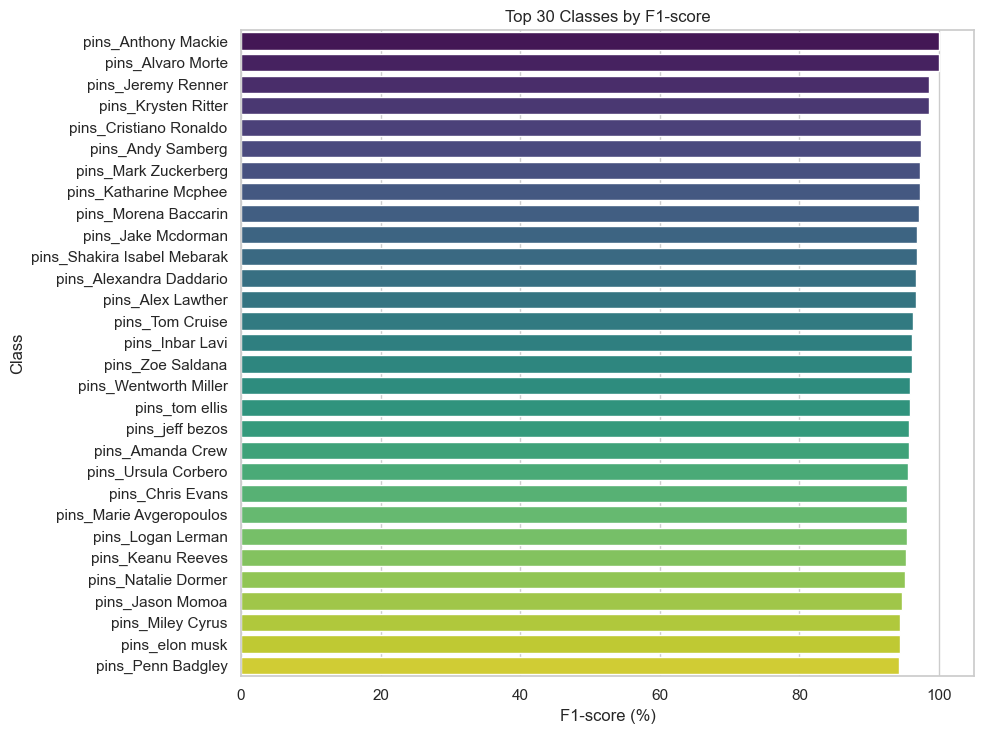

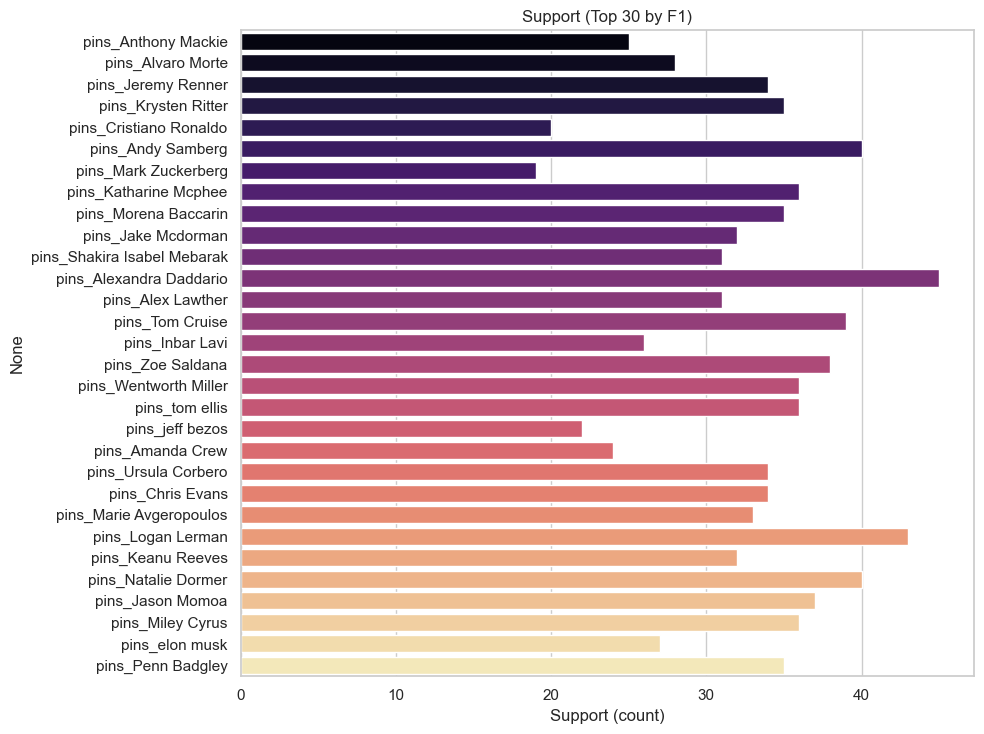

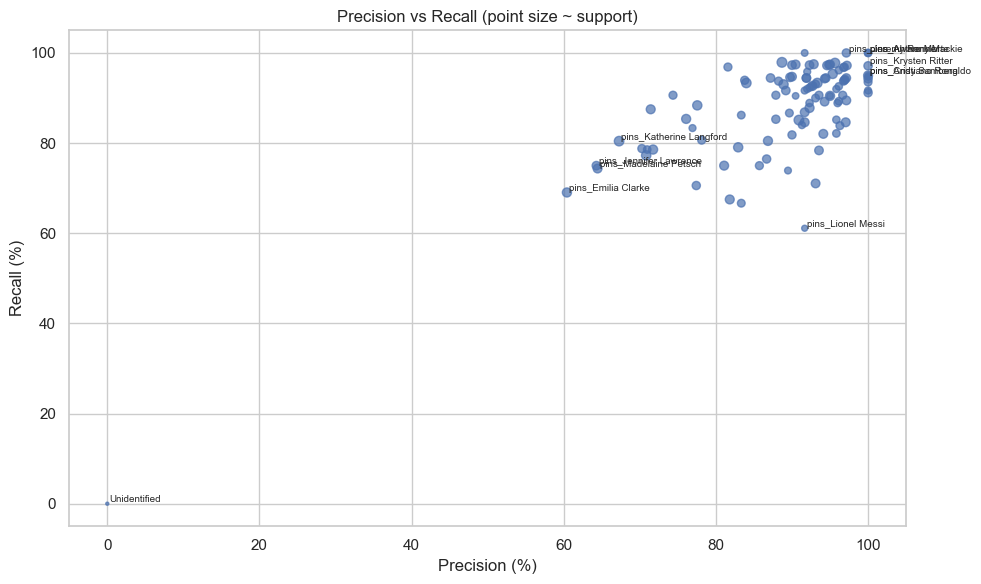

Saved parsed metrics to ./report_visuals\parsed_metrics_from_preds.csv


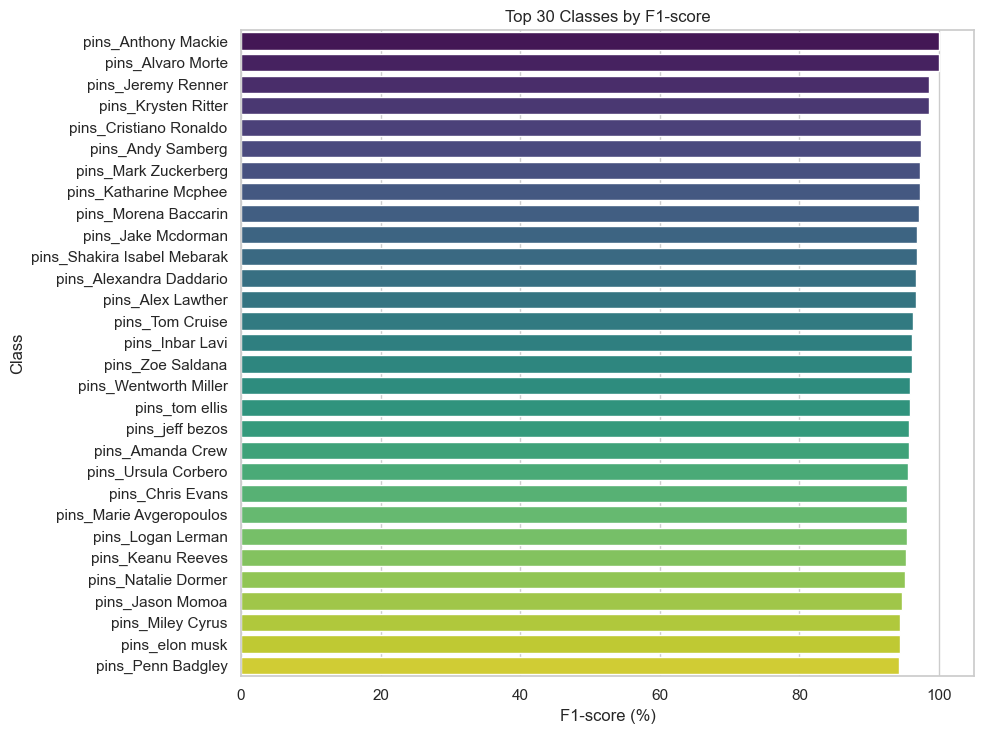

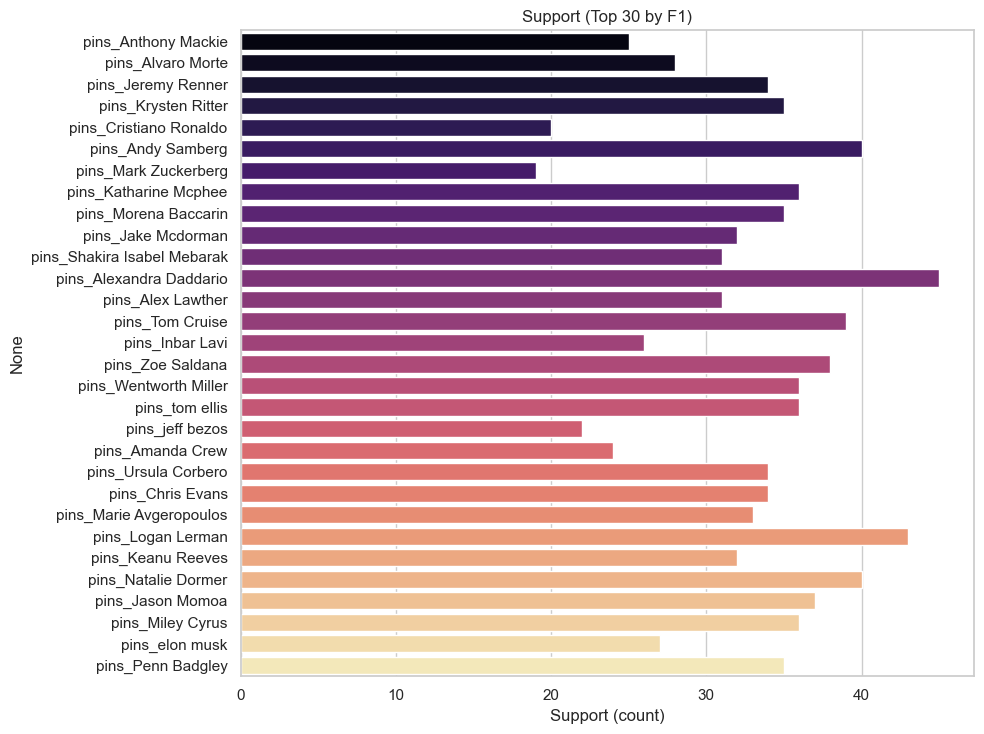

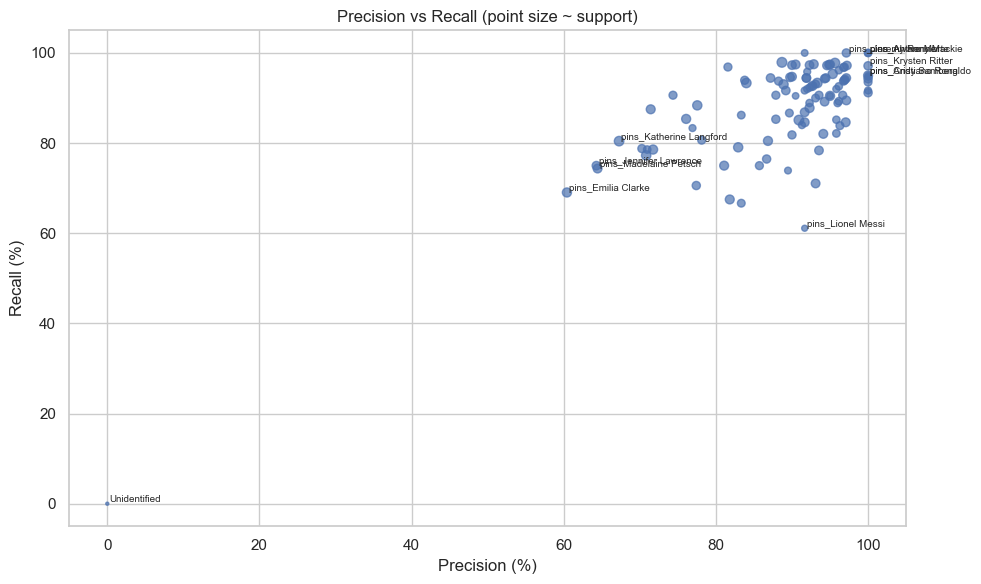

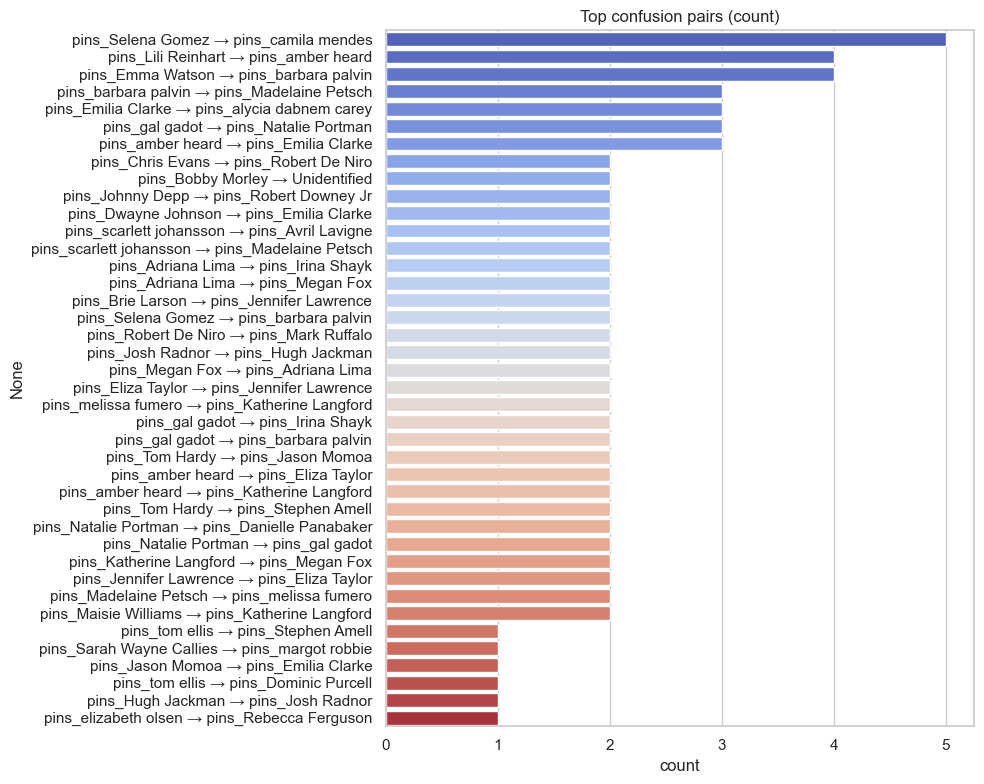

Saved summary CSVs and images to ./report_visuals


In [ ]:
sns.set(style="whitegrid")
out_dir = './report_visuals'
os.makedirs(out_dir, exist_ok=True)
# Obtain predictions and ground truth from workspace if available
if 'y_true' in globals() and 'y_pred' in globals():
    y_true_local = list(y_true)
    y_pred_local = list(y_pred)
else:
    # Try reading previously saved parsed metrics (fallback)
    parsed_path = os.path.join(out_dir, 'parsed_metrics.csv')
    raise RuntimeError(f'y_true/y_pred not found in notebook. Run evaluation cell first or provide {parsed_path}')
# Build classification report dict and DataFrame
report_dict = classification_report(y_true_local, y_pred_local, output_dict=True, zero_division=0)
df_report = pd.DataFrame(report_dict).transpose()
# Filter out aggregate rows if present and keep only class rows
class_rows = [r for r in df_report.index if r not in ('accuracy','macro avg','weighted avg')]
df_classes = df_report.loc[class_rows].copy()
# Ensure numeric columns exist and convert types
for col in ['precision','recall','f1-score','support']:
    if col in df_classes.columns:
        df_classes[col] = pd.to_numeric(df_classes[col], errors='coerce')
# If metrics are in [0,1] convert to percentages
for m in ['precision','recall','f1-score']:
    if df_classes[m].max() <= 1.0:
        df_classes[m] = df_classes[m] * 100.0
# Sort by F1-score for ranking plots
df_classes = df_classes.sort_values('f1-score', ascending=False)
# Save parsed metrics CSV
csv_path = os.path.join(out_dir, 'parsed_metrics_from_preds.csv')
df_classes.to_csv(csv_path)
print('Saved parsed metrics to', csv_path)
# --- Plot 1: Top K by F1-score (horizontal bar) ---
TOP_K = 30
topk = df_classes.head(TOP_K).copy()
plt.figure(figsize=(10, max(4, 0.25*len(topk))))
sns.barplot(x='f1-score', y=topk.index, data=topk, palette='viridis')
plt.xlabel('F1-score (%)')
plt.ylabel('Class')
plt.title(f'Top {min(TOP_K,len(topk))} Classes by F1-score')
plt.tight_layout()
plt.savefig(os.path.join(out_dir, 'topk_f1.png'), dpi=150)
plt.show()
# --- Plot 2: Support counts (Top K) ---
plt.figure(figsize=(10, max(4, 0.25*len(topk))))
sns.barplot(x='support', y=topk.index, data=topk, palette='magma')
plt.xlabel('Support (count)')
plt.title(f'Support (Top {min(TOP_K,len(topk))} by F1)')
plt.tight_layout()
plt.savefig(os.path.join(out_dir, 'topk_support.png'), dpi=150)
plt.show()
# --- Plot 3: Precision vs Recall scatter (size ~ support) ---
plt.figure(figsize=(10,6))
sizes = (df_classes['support'] - df_classes['support'].min() + 1).clip(lower=5)
plt.scatter(df_classes['precision'], df_classes['recall'], s=sizes, alpha=0.7)
# Label extreme outliers to help inspection
for i,row in df_classes.iterrows():
    if (row['f1-score'] <= df_classes['f1-score'].quantile(0.05)) or (row['f1-score'] >= df_classes['f1-score'].quantile(0.95)):
        plt.text(row['precision']+0.3, row['recall']+0.3, i, fontsize=7)
plt.xlabel('Precision (%)')
plt.ylabel('Recall (%)')
plt.title('Precision vs Recall (point size ~ support)')
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(out_dir, 'precision_vs_recall.png'), dpi=150)
plt.show()
# --- Confusion insights: show full matrix if small, otherwise top confusion pairs ---
labels = list(df_classes.index)
n_labels = len(labels)
if n_labels <= 40:
    cm = confusion_matrix(y_true_local, y_pred_local, labels=labels)
    cm_df = pd.DataFrame(cm, index=labels, columns=labels)
    plt.figure(figsize=(12, max(8, 0.2*n_labels)))
    sns.heatmap(cm_df, cmap='Blues', fmt='d')
    plt.title('Confusion Matrix (rows=true, cols=pred)')
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, 'confusion_matrix.png'), dpi=150)
    plt.show()
else:
    # Show top confused pairs for large label sets
    cm = confusion_matrix(y_true_local, y_pred_local, labels=labels)
    cm_df = pd.DataFrame(cm, index=labels, columns=labels)
    # zero diagonal (correct predictions) and flatten to find top confusions
    cm_no_diag = cm_df.copy()
    np.fill_diagonal(cm_no_diag.values, 0)
    stacked = cm_no_diag.stack().reset_index()
    stacked.columns = ['true','pred','count']
    top_confusions = stacked.sort_values('count', ascending=False).head(40)
    plt.figure(figsize=(10,8))
    sns.barplot(x='count', y=top_confusions.apply(lambda r: f"{r['true']} → {r['pred']}", axis=1), data=top_confusions, palette='coolwarm')
    plt.title('Top confusion pairs (count)')
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, 'top_confusions.png'), dpi=150)
    plt.show()
# --- Summary tables: save top and bottom performers by F1 ---
df_classes.reset_index(inplace=True)
df_classes.rename(columns={'index':'label','f1-score':'f1_score'}, inplace=True)
df_classes[['label','precision','recall','f1_score','support']].head(10).to_csv(os.path.join(out_dir,'top10_f1.csv'), index=False)
df_classes[['label','precision','recall','f1_score','support']].tail(10).to_csv(os.path.join(out_dir,'bottom10_f1.csv'), index=False)
print('Saved summary CSVs and images to', out_dir)

In [19]:
!pip install plotly
!pip install -U kaleido


[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip



   ---------------------------------------- 0/9 [simplejson]
   ---------------------------------------- 0/9 [simplejson]
   ---------------------------------------- 0/9 [simplejson]
   ---- ----------------------------------- 1/9 [pluggy]
   ----------------- ---------------------- 4/9 [iniconfig]
   ---------------------- ----------------- 5/9 [pytest]
   ---------------------- ----------------- 5/9 [pytest]
   ---------------------- ----------------- 5/9 [pytest]
   ---------------------- ----------------- 5/9 [pytest]
   ---------------------- ----------------- 5/9 [pytest]
   ---------------------- ----------------- 5/9 [pytest]
   ---------------------- ----------------- 5/9 [pytest]
   ---------------------- ----------------- 5/9 [pytest]
   ---------------------- ----------------- 5/9 [pytest]
   ---------------------- ----------------- 5/9 [pytest]
   ---------------------- ----------------- 5/9 [pytest]
   ---------------------- ----------------- 5/9 [pytest]
   ------------


[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Wrote interactive confusion matrix to ./report_visuals\confusion_matrix_interactive.html
Wrote PNG: ./report_visuals\confusion_matrix_interactive.png
Wrote normalized confusion matrix to ./report_visuals\confusion_matrix_normalized_interactive.html
Wrote PNG: ./report_visuals\confusion_matrix_normalized.png
Wrote grouped metric bars to ./report_visuals\precision_recall_f1_grouped.html
Wrote PNG: ./report_visuals\precision_recall_f1_grouped.png
Wrote stacked prediction distribution to ./report_visuals\prediction_distribution_stacked.html
Wrote PNG: ./report_visuals\prediction_distribution_stacked.png
Interactive + image visuals saved to ./report_visuals


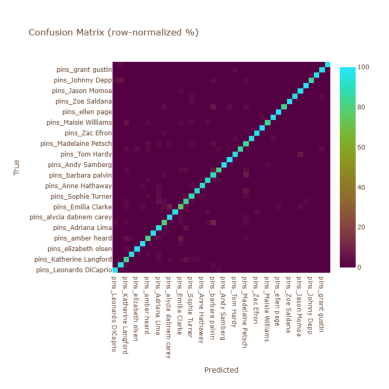

In [24]:
img = cv2.imread("./report_visuals/confusion_matrix_normalized.png")
plt.imshow(img)
plt.axis('off')
plt.show()